# Projet Volumes Finis — Advection d'un constituant dans un labyrinthe
**GCVIV0185-7 — Méthodes numériques linéaires en génie civil et géologique (2026-2027)**
Auteur : Daniel Olumi

Résolution par Volumes Finis de l'advection d'un constituant, $\dfrac{\partial c}{\partial t}+\dfrac{\partial (uc)}{\partial x}+\dfrac{\partial (vc)}{\partial y}=0$, dans le champ de vitesse d'un labyrinthe ; validation et analyse des résultats (stabilité temporelle, précision spatiale).

**Deux versions du schéma** (choisies par les paramètres de `simuler`, cellule suivante) :
* **Version 1 : Euler + reconstruction constante** ;
* **Version 2 : Runge-Kutta 2 + reconstruction linéaire** (avec limiteur de Barth-Jespersen ; `limiteur=None` donne la version sans limiteur).

**Plan** : 1. Potentiel — 2. Vitesses aux bords — 3. Labyrinthe : les deux versions et animation — 4. Validation sur un canal — 5. Stabilité — 6. Synthèse.

| Module | Rôle |
|---|---|
| `laplace_only.py` | code fourni (dépôt `HECE/labyrinth_public`), utilisé sans modification |
| `potentiel.py` | lecture de l'image, appel de `laplace_pot`, passage à nos conventions |
| `domaine.py` | grille régulière, types des faces (mur / intérieur / entrée / sortie) |
| `vitesses.py` | vitesses normales aux bords, divergence, débits, pas de temps CFL |
| `volumes_finis.py` | reconstruction, flux amont, bilan, Euler / RK2 |
| `validation.py` | tests : précision des vitesses, translation, convergence, stabilité |
| `affichage.py` | figures et animation |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from potentiel import potentiel_labyrinthe      # appelle laplace_pot (code fourni)
from vitesses import vitesses_aux_bords, divergence, debits_bords
from volumes_finis import simuler
from affichage import carte, carte_vitesse, serie, bilan_masse, animer
import validation as val
plt.rcParams['figure.dpi'] = 80

# les deux versions du schéma
VERSION_1 = dict(schema='euler', reconstruction='constante', limiteur=None)    # Euler + constante
VERSION_2 = dict(schema='rk2', reconstruction='lineaire', limiteur='barth')    # RK2 + linéaire (limitée)

## 1. Potentiel des vitesses (code fourni)
Le potentiel est calculé par `laplace_pot` (code fourni, non modifié) avec $\phi=0$ sur l'entrée (haut) et $\phi=1$ sur la sortie (bas). Préparation faite dans `potentiel.py` : un bloc de $4\times4$ pixels devient une maille (fluide seulement si tous ses pixels sont blancs), les poches fluides isolées sont supprimées, puis le résultat est remis dans le sens de l'axe $y$ vers le haut.

Domaine(125 x 125 mailles, dx=0.008, dy=0.008, 11486 mailles fluides, 5 faces d'entrée, 5 faces de sortie)
mailles à potentiel imposé (entrée + sortie) : 10
contrôle : écart avec out_pot.npy du dépôt fourni = 8.0e-11


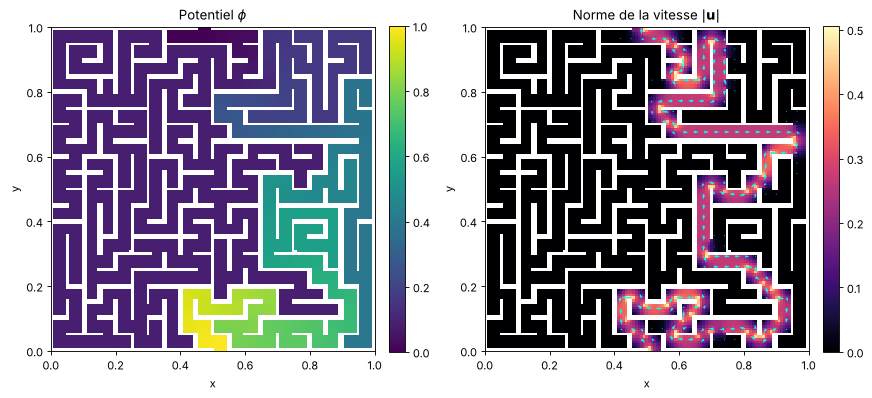

In [2]:
dom, phi = potentiel_labyrinthe('donnees/laby.png', facteur=4, phi_entree=0.0, phi_sortie=1.0)
print(dom)
print('mailles à potentiel imposé (entrée + sortie) :', dom.cl.sum())
print('contrôle : écart avec out_pot.npy du dépôt fourni =', f'{val.comparer_reference_prof():.1e}')
u, v = vitesses_aux_bords(dom, phi)
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
carte(dom, phi, r'Potentiel $\phi$', ax=ax[0])
carte_vitesse(dom, u, v, r'Norme de la vitesse $|\mathbf{u}|$', ax=ax[1])
plt.tight_layout(); plt.show()

**Observation.** L'écart de $10^{-10}$ avec le fichier du dépôt confirme que l'appel au code fourni est correct (convention $\mathbf u=+\nabla\phi$ de l'énoncé : l'eau va de $\phi=0$ vers $\phi=1$).
Le potentiel est **constant dans chaque cul-de-sac** : un bras sans issue n'a qu'une « porte », aucun gradient ne peut s'y établir, donc la vitesse y est nulle. L'écoulement ne parcourt que le **chemin entrée → sortie** : c'est pour cela qu'il « résout » le labyrinthe. La vitesse est maximale aux coins de l'ouverture d'entrée (potentiel uniforme imposé sur toute l'ouverture).

## 2. Vitesses normales aux bords
$\phi$ est connu au centre des mailles ; la vitesse normale d'un bord intérieur est la différence centrée $u=(\phi_{droite}-\phi_{gauche})/\Delta x$ (de même pour $v$). Bord de mur : $u=0$. Bord extérieur d'une maille d'entrée ou de sortie : déduit de la continuité de la maille (le code fourni ne donne pas $\phi$ au-delà).

In [3]:
div = divergence(dom, u, v)
q_in, q_out = debits_bords(dom, u, v)
echelle = np.abs(u).max() / dom.dx          # ordre de grandeur d'un terme du/dx
print(f"max |div|           = {np.nanmax(np.abs(div)):.2e}")
print(f"max |div| relative  = {np.nanmax(np.abs(div))/echelle:.2e}")
print(f"débit entrant = {q_in:.10f}   débit sortant = {q_out:.10f}")

max |div|           = 2.43e-11
max |div| relative  = 3.90e-13
débit entrant = 0.0107460080   débit sortant = 0.0107460080


**Observation.** Divergence nulle au zéro machine et débit entrant = débit sortant : le champ est **discrètement incompressible**. Ce n'est pas un hasard : la divergence discrète d'une maille, $\frac{u_E-u_W}{\Delta x}+\frac{v_N-v_S}{\Delta y}$, est exactement l'équation que le code fourni a résolue pour cette maille. C'est ce qui rend équivalentes la forme conservative et la forme non conservative de l'énoncé ($c\,\nabla\cdot\mathbf u=0$).

**Précision des vitesses** : test sur une fonction connue $\phi=e^x\cos y$ (Laplacien nul), comparée à la dérivée exacte au milieu de chaque bord.

ordre observé : [1.93 1.96 1.98 1.99]


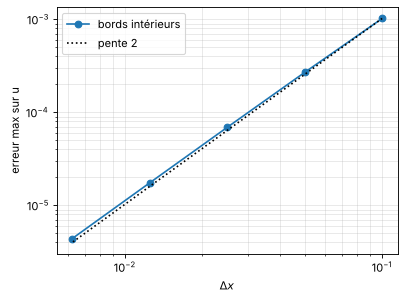

In [4]:
dxs, e_int = val.precision_vitesses()
plt.figure(figsize=(5.5, 4))
plt.loglog(dxs, e_int, 'o-', label='bords intérieurs')
plt.loglog(dxs, e_int[0]*(dxs/dxs[0])**2, 'k:', label='pente 2')
plt.xlabel(r'$\Delta x$'); plt.ylabel('erreur max sur u'); plt.legend(); plt.grid(True, which='both', alpha=.3)
plt.show()
print('ordre observé :', np.round(np.log2(e_int[:-1]/e_int[1:]), 2))

**Observation.** Pente 2 : la différence est **centrée sur le bord**, l'erreur est d'ordre 2. Dans le labyrinthe, la précision réelle est limitée par la résolution (environ 5 mailles par couloir), les murs en escalier, les coins rentrants et le profil d'entrée imposé ; la divergence nulle, elle, est garantie exactement.

## 3. Le labyrinthe : les deux versions
Schéma (`volumes_finis.py`) : bilan des flux sur les 4 bords de chaque maille ; **un seul flux par bord**, pris du côté **amont** ; reconstruction constante ou linéaire ; conditions faibles ($c=1$ sur l'entrée, flux nul aux murs) ; $\Delta t=\text{CFL}\times\Delta t_{max}$, $\Delta t_{max}=1/\max(|u|/\Delta x+|v|/\Delta y)$, CFL $=0{,}9$.
Au départ $c=0$ partout ; on injecte $c=1$ par l'entrée.

  EULER / constante : 2720 pas, dt = 7.353e-03 (CFL = 0.90)
  RK2 / lineaire + barth : 2720 pas, dt = 7.353e-03 (CFL = 0.90)
Version 1 : écart de conservation 1.7e-15   min c = 0.0e+00   max c = 1.000000
Version 2 : écart de conservation 2.7e-15   min c = -4.5e-20   max c = 1.000000


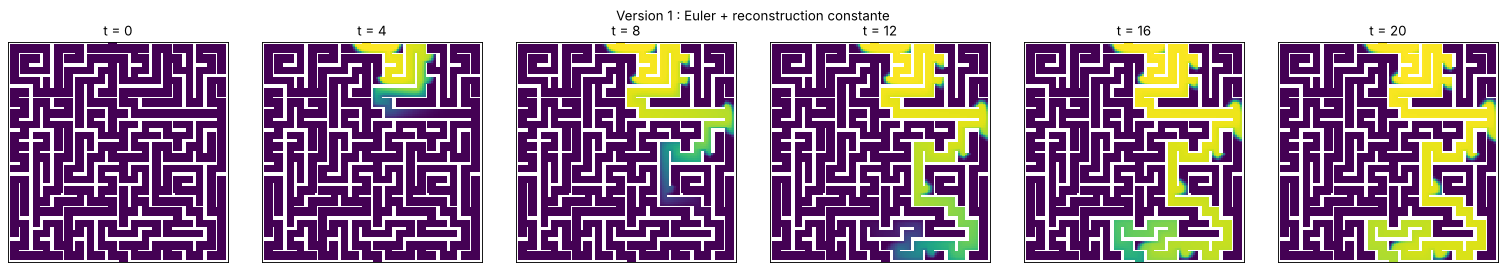

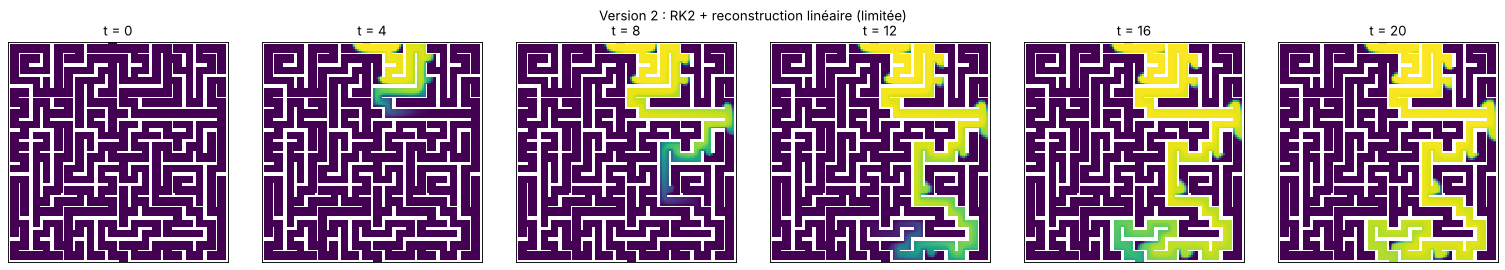

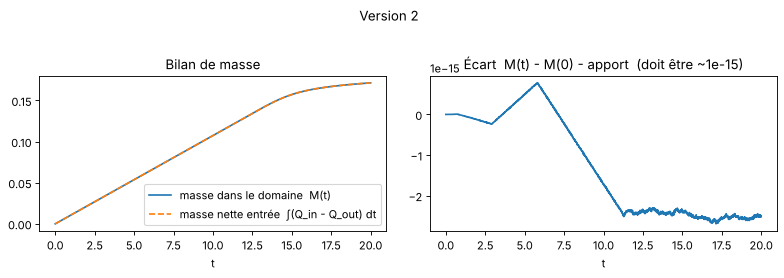

In [5]:
c0 = np.zeros((dom.ny, dom.nx))
res1 = simuler(dom, u, v, c0, t_final=20.0, cfl=0.9, c_entree=1.0, n_sauvegardes=5, **VERSION_1)
res2 = simuler(dom, u, v, c0, t_final=20.0, cfl=0.9, c_entree=1.0, n_sauvegardes=5, **VERSION_2)
serie(dom, res1, titre='Version 1 : Euler + reconstruction constante'); plt.show()
serie(dom, res2, titre='Version 2 : RK2 + reconstruction linéaire (limitée)'); plt.show()
for nom, r in (('Version 1', res1), ('Version 2', res2)):
    ecart = r['masse'] - r['masse'][0] - r['apport']
    print(f"{nom} : écart de conservation {np.abs(ecart).max():.1e}   min c = {r['c'][-1].min():.1e}   max c = {r['c'][-1].max():.6f}")
bilan_masse(res2, 'Version 2'); plt.show()

**Observations.**
* Le constituant suit le chemin entrée → sortie ; les culs-de-sac (vitesse nulle) restent propres, sauf une petite tache à leur embouchure.
* **Version 1** : front plus **étalé** (diffusion numérique d'un schéma d'ordre 1). **Version 2** : front plus **net** (ordre 2) et $0\le c\le1$ grâce au limiteur.
* **Masse conservée à $10^{-15}$ près** pour les deux versions : conséquence directe de la forme conservative (ce qui sort d'une maille entre dans la voisine, flux nuls aux murs). La masse se stabilise vers $t\approx15$ : le colorant atteint la sortie et il en sort autant qu'il en entre.

  EULER / constante : 1088 pas, dt = 7.353e-03 (CFL = 0.90)
  RK2 / constante : 1088 pas, dt = 7.353e-03 (CFL = 0.90)
  RK2 / lineaire : 1088 pas, dt = 7.353e-03 (CFL = 0.90)
  RK2 / lineaire + barth : 1088 pas, dt = 7.353e-03 (CFL = 0.90)
  EULER / lineaire : 1088 pas, dt = 7.353e-03 (CFL = 0.90)


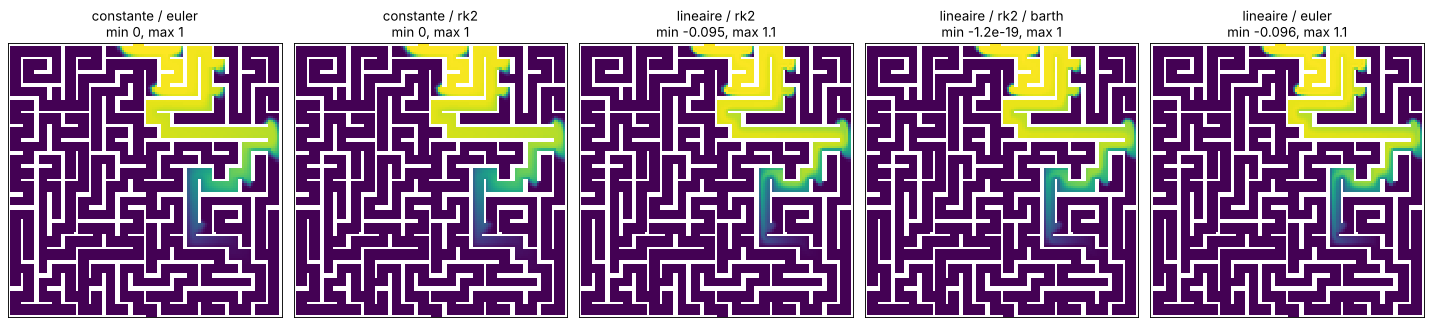

In [6]:
t_cmp = 8.0
resultats = {}
for rec, sch, lim in [('constante', 'euler', None), ('constante', 'rk2', None),
                      ('lineaire', 'rk2', None), ('lineaire', 'rk2', 'barth'), ('lineaire', 'euler', None)]:
    nom = f'{rec} / {sch}' + (f' / {lim}' if lim else '')
    resultats[nom] = simuler(dom, u, v, c0, t_cmp, cfl=0.9, schema=sch, reconstruction=rec,
                             limiteur=lim, n_sauvegardes=1)
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, (nom, r) in zip(axes, resultats.items()):
    cfin = r['c'][-1]
    carte(dom, np.clip(cfin, -0.2, 1.2), f"{nom}\nmin {np.nanmin(cfin):.2g}, max {np.nanmax(cfin):.3g}",
          ax=ax, vmin=0, vmax=1, barre=False)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.show()

**Observations** (comparaison à $t=8$).
* **Linéaire sans limiteur** : front raide mais $c<0$ et $c>1$, non physiques : un schéma linéaire d'ordre 2 ne peut pas être monotone (Godunov). Le limiteur supprime ces dépassements.
* **Linéaire + Euler** : ne diverge pas ici alors que l'analyse (section 5) le prédit instable. L'instabilité est faible ($|\rho|\approx1{,}01$ pour un Courant de 0,25, typique des couloirs) et les perturbations sortent avec le front ; dans le canal (section 4) le même schéma explose. Un schéma se choisit stable par l'analyse, pas parce qu'il « semble marcher » sur un cas.

### 3.1 Animation (Version 2)
Régénérée par la cellule suivante (environ 1 minute) et enregistrée dans `ecoulement.gif`.

  RK2 / lineaire + barth : 2720 pas, dt = 7.353e-03 (CFL = 0.90)


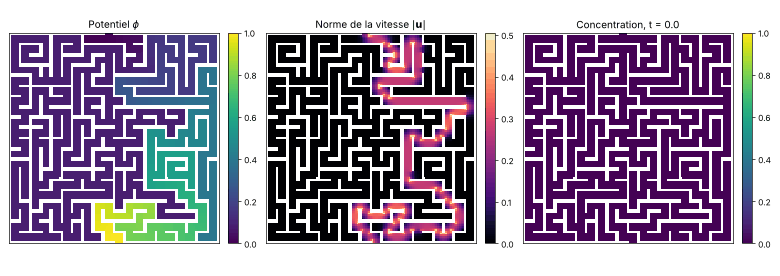

In [7]:
from IPython.display import Image, display
res_anim = simuler(dom, u, v, c0, t_final=20.0, cfl=0.9, c_entree=1.0, n_sauvegardes=50, **VERSION_2)
fichier = animer(dom, phi, u, v, res_anim, 'ecoulement.gif')
display(Image(filename=fichier))

## 4. Validation : canal rectiligne
Canal vertical de longueur 1 ; avec $\phi_{entrée}=0$ et $\phi_{sortie}=(n-1)\Delta y$, le code fourni donne $v=-1$ exactement et $u=0$. La solution exacte est une **translation** du profil initial : $c(s,t)=c_0(s-t)$, $s$ = distance depuis l'entrée. Ce test vérifie toute la chaîne : potentiel → vitesses → volumes finis.

vitesse obtenue dans le canal : v min/max = -1.0000000000000397 -0.9999999999999565


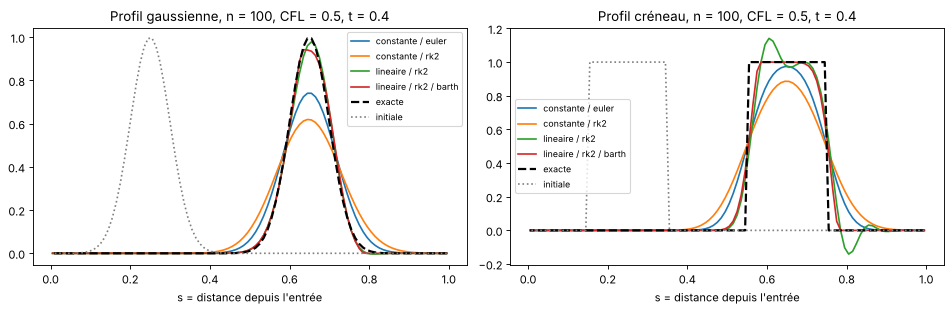

In [8]:
_, _, _, _, vc = val.translation_canal(100)
print('vitesse obtenue dans le canal : v min/max =', vc[vc != 0].min(), vc[vc != 0].max())

configs = [('constante', 'euler', None), ('constante', 'rk2', None),
           ('lineaire', 'rk2', None), ('lineaire', 'rk2', 'barth')]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, profil, nom in ((axes[0], val.profil_gauss, 'gaussienne'), (axes[1], val.profil_creneau, 'créneau')):
    for rec, sch, lim in configs:
        x, c, ce, res, _ = val.translation_canal(100, profil, t_final=0.4, reconstruction=rec,
                                                 schema=sch, limiteur=lim, cfl=0.5)
        ax.plot(x, c, label=f'{rec} / {sch}' + (f' / {lim}' if lim else ''))
    ax.plot(x, ce, 'k--', lw=2, label='exacte')
    ax.plot(x, profil(x), ':', color='gray', label='initiale')
    ax.set_title(f'Profil {nom}, n = 100, CFL = 0.5, t = 0.4'); ax.set_xlabel('s = distance depuis l\'entrée'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Observations.**
* **Constante (version 1)** : le profil avance à la bonne vitesse mais s'**étale** : c'est la diffusion numérique du schéma amont d'ordre 1 (terme $\frac{u\Delta x}{2}(1-\lambda)\,c_{xx}$ de l'équation équivalente, proportionnel à $\Delta x$).
* **Linéaire sans limiteur** : beaucoup moins étalé, mais oscillations près des discontinuités du créneau (Godunov).
* **Linéaire limitée (version 2)** : pas d'oscillation, sommet de la gaussienne légèrement écrêté.

**Ordre de convergence** : erreur $L_1$ sur la gaussienne pour $n=50$ à $800$ mailles (CFL = 0,5).

constante / euler              ordres observés : [0.69 0.81 0.89 0.94]
constante / rk2                ordres observés : [0.56 0.69 0.8  0.88]
lineaire / rk2                 ordres observés : [1.77 1.95 1.99 2.  ]
lineaire / rk2 / barth         ordres observés : [1.42 1.69 1.78 1.88]


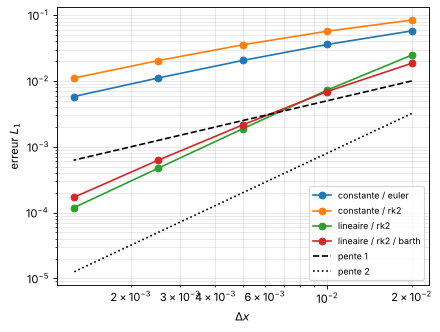

In [9]:
plt.figure(figsize=(6, 4.5))
tableau = []
for rec, sch, lim in configs:
    dxs, e1, einf, ordre = val.convergence((50, 100, 200, 400, 800), reconstruction=rec,
                                           schema=sch, limiteur=lim, cfl=0.5)
    nom = f'{rec} / {sch}' + (f' / {lim}' if lim else '')
    plt.loglog(dxs, e1, 'o-', label=nom)
    tableau.append((nom, ordre))
plt.loglog(dxs, 0.5*dxs, 'k--', label='pente 1'); plt.loglog(dxs, 8*dxs**2, 'k:', label='pente 2')
plt.xlabel(r'$\Delta x$'); plt.ylabel('erreur $L_1$'); plt.legend(fontsize=8); plt.grid(True, which='both', alpha=.3)
plt.show()
for nom, o in tableau:
    print(f'{nom:30s} ordres observés : {np.round(o, 2)}')

**Observations.**
* Constante : **ordre 1** ; linéaire + RK2 : **ordre 2**, comme le prévoit l'ordre $\min(r+1,\,2n_G)-\beta$ avec $r=1$, un point de Gauss au milieu du bord ($n_G=1$) et un maillage régulier ($\beta=0$).
* Le limiteur ramène localement l'ordre vers 1 aux extrema (écrêtage) : ordre global entre 1,4 et 1,9, qui tend vers 2 en raffinant.
* À $\Delta x$ fixé, constante + Euler est un peu plus précis que constante + RK2 : l'erreur en temps d'Euler (anti-diffusive) compense en partie la diffusion spatiale. Améliorer seulement l'ordre en temps n'améliore pas un schéma limité par l'ordre en espace.
* Linéaire + Euler n'apparaît pas : il diverge (cellule suivante).

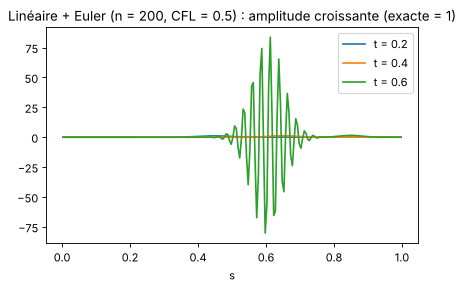

In [10]:
plt.figure(figsize=(6, 3.5))
for tf in (0.2, 0.4, 0.6):
    x, c, ce, res, _ = val.translation_canal(200, val.profil_gauss, t_final=tf, reconstruction='lineaire',
                                             schema='euler', cfl=0.5)
    plt.plot(x, c, label=f't = {tf}')
plt.title('Linéaire + Euler (n = 200, CFL = 0.5) : amplitude croissante (exacte = 1)'); plt.xlabel('s'); plt.legend()
plt.show()

## 5. Stabilité temporelle
Facteur d'amplification $\max_\theta|\rho|$ calculé pour chaque combinaison (analyse de Von Neumann, `validation.amplification`), en fonction du nombre de Courant $\lambda=u\Delta t/\Delta x$ ; à droite, zone stable en 2D pour la version 1.

lambda = 0.25: linéaire/Euler max|rho| = 1.0099
lambda = 0.5: linéaire/Euler max|rho| = 1.0887
lambda = 1.0: linéaire/Euler max|rho| = 1.5936


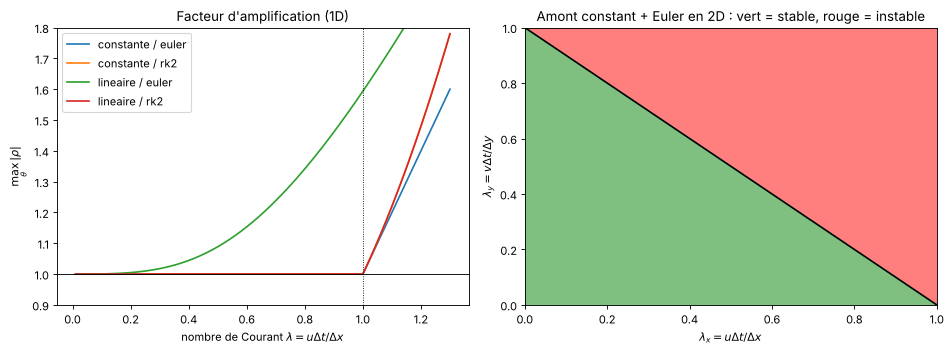

In [11]:
lams = np.linspace(0.01, 1.3, 130)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for rec in ('constante', 'lineaire'):
    for sch in ('euler', 'rk2'):
        axes[0].plot(lams, [val.amplification(l, rec, sch) for l in lams], label=f'{rec} / {sch}')
axes[0].axhline(1, color='k', lw=.8); axes[0].axvline(1, color='k', ls=':', lw=.8)
axes[0].set_xlabel(r'nombre de Courant $\lambda=u\Delta t/\Delta x$'); axes[0].set_ylabel(r'$\max_\theta|\rho|$')
axes[0].set_ylim(0.9, 1.8); axes[0].legend(); axes[0].set_title('Facteur d\'amplification (1D)')
LX, LY, R = val.carte_amplification_2d()
axes[1].contourf(LX, LY, R > 1e-12, levels=[-.5, .5, 1.5], colors=['#7fbf7f', '#ff7f7f'])
axes[1].plot([0, 1], [1, 0], 'k-')
axes[1].set_xlabel(r'$\lambda_x=u\Delta t/\Delta x$'); axes[1].set_ylabel(r'$\lambda_y=v\Delta t/\Delta y$')
axes[1].set_title("Amont constant + Euler en 2D : vert = stable, rouge = instable")
plt.tight_layout(); plt.show()
for l in (0.25, 0.5, 1.0):
    print(f'lambda = {l}: linéaire/Euler max|rho| = {val.amplification(l, "lineaire", "euler"):.4f}')

**Observations.**
* Version 1 (constante + Euler) et version 2 (linéaire + RK2) : stables jusqu'à $\lambda=1$ (les courbes RK2 sont superposées).
* **Linéaire + Euler : $|\rho|>1$ pour tout $\lambda$**, donc instable : c'est ce qu'on a vu dans le canal. La reconstruction linéaire ajoute une partie centrée que l'Euler explicite amplifie ; RK2 la stabilise. D'où l'association « RK2 + linéaire ».
* En 2D la zone stable est le triangle $\lambda_x+\lambda_y\le1$, plus restrictif qu'en 1D : vérification numérique ci-dessous.

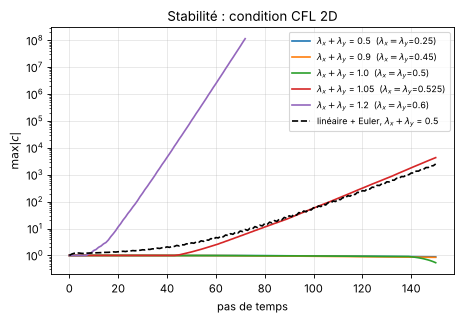

In [12]:
plt.figure(figsize=(6.5, 4))
for s in (0.5, 0.9, 1.0, 1.05, 1.2):
    cm, c, d = val.stabilite_cfl_2d(s, n=100, n_pas=150)
    plt.semilogy(cm, label=fr'$\lambda_x+\lambda_y$ = {s}  ($\lambda_x=\lambda_y$={s/2:.3g})')
cm, c, d = val.stabilite_cfl_2d(0.5, n=100, n_pas=150, schema='euler', reconstruction='lineaire')
plt.semilogy(cm, 'k--', label='linéaire + Euler, $\\lambda_x+\\lambda_y$ = 0.5')
plt.xlabel('pas de temps'); plt.ylabel(r'$\max|c|$'); plt.legend(fontsize=8); plt.grid(alpha=.3)
plt.title('Stabilité : condition CFL 2D'); plt.show()

**Observation.** Transport en diagonale ($u=v=1$) d'un carré, version 1 : stable jusqu'à $\lambda_x+\lambda_y=1$, explosion au-delà, **alors que chaque $\lambda$ pris seul vaut 0,6 < 1** pour la courbe 1,2. Linéaire + Euler diverge même à 0,5. C'est pourquoi le code calcule $\Delta t$ avec le critère 2D, maille par maille, multiplié par CFL $=0{,}9<1$. Dans le labyrinthe, CFL $=1{,}2$ ne diverge pas : $\Delta t_{max}$ est fixé par la vitesse maximale (coins de l'entrée, où $c=1$ est uniforme) et le Courant local dans les couloirs reste $<1$ ; il faut CFL $=3$ pour une explosion.

## 6. Synthèse : résultats et lien avec la théorie

| Résultat observé | Explication |
|---|---|
| culs-de-sac à vitesse nulle | potentiel constant dans un bras à une seule porte |
| divergence $\approx10^{-11}$, débits égaux | divergence discrète = équation résolue par le code fourni |
| vitesses aux bords d'ordre 2 | différence centrée sur le bord |
| masse conservée à $10^{-15}$ | forme conservative : un seul flux par bord |
| version 1 : front étalé, ordre 1 | amont d'ordre 1 : diffusion numérique en $\Delta x$ |
| version 2 : front net, ordre 2 | reconstruction linéaire, $\min(r+1,2n_G)-\beta=2$ |
| linéaire sans limiteur : $c<0$, $c>1$ | Godunov ; le limiteur rétablit $0\le c\le1$ |
| linéaire + Euler instable | $|\rho|>1$ ; RK2 stabilise |
| stable si $\lambda_x+\lambda_y\le1$ | condition CFL 2D |

**Limites** : résolution grossière (environ 5 mailles par couloir, murs en escalier ; `facteur=2` coûte 8 fois plus), potentiel uniforme imposé sur l'ouverture d'entrée (vitesse forte aux coins), pas de temps unique fixé par la vitesse maximale.